# Chapter 01: Quantifying Uncertainty — Python Laboratory
### *From Binary Entropy to Continuous Beta Posteriors and Operational Risk*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/01_quantifying_uncertainty_entropy_and_bayes.ipynb) | [Prev: Ch 00: The Physics of Belief (Python)](00_the_physics_of_belief.ipynb) | [Next: Ch 02: Relative Entropy (Python)](02_relative_entropy_and_prior_penalties.ipynb)**

---

## 1. From Individual Surprise to Average Ignorance

In Chapter 00, we measured the surprise of a *single* outcome $I(p) = -\log_2 p$. Now suppose we want to measure the **total uncertainty of a random variable before we observe it**.

**Shannon Entropy** $H(X)$ is the expected (probability-weighted average) surprise across all possible outcomes:
$$H(X) = \mathbb{E}[I(X)] = -\sum_{x} P(x) \log_2 P(x) \quad \text{[bits]}$$

For a binary event with probability $\theta$ (e.g., a test failing with rate $\theta$), this reduces to the **Binary Entropy Function**:
$$H_2(\theta) = -\theta \log_2 \theta - (1 - \theta) \log_2(1 - \theta)$$

Let's import our libraries and verify the shape of $H_2(\theta)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist
from scipy.special import betaln, psi

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. The Binary Entropy Function $H_2(\theta)$

Notice the key physical properties of $H_2(\theta)$:
* **Maximum ignorance at $\theta = 0.5$:** $H_2(0.5) = 1.0\text{ bit}$. You need 1 full yes/no question to learn the outcome of a fair coin.
* **Zero uncertainty at $\theta \in \{0, 1\}$:** $H_2(0) = H_2(1) = 0\text{ bits}$ (using the convention $0 \log_2 0 = 0$).
* **Strictly concave:** Mixing two distributions can only *increase* or preserve uncertainty—never decrease it.

Failure Rate theta     | Binary Entropy H2 (Bits) 
0.00                   | 0.0000                   
0.01                   | 0.0808                   
0.05                   | 0.2864                   
0.10                   | 0.4690                   
0.25                   | 0.8113                   
0.50                   | 1.0000                   
0.75                   | 0.8113                   
0.90                   | 0.4690                   
0.99                   | 0.0808                   
1.00                   | 0.0000                   


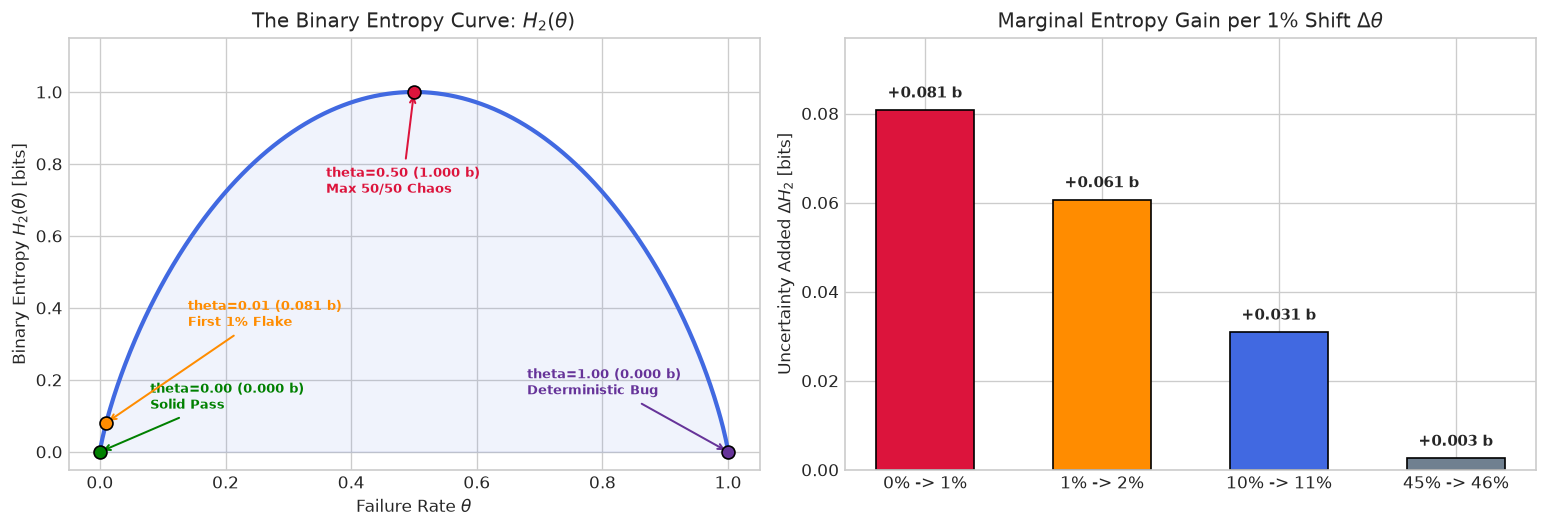

In [2]:
def binary_entropy(theta):
    # Vectorized binary Shannon entropy in bits
    theta = np.asarray(theta, dtype=np.float64)
    # Clip to avoid log(0) while maintaining continuity
    eps = 1e-15
    theta_safe = np.clip(theta, eps, 1.0 - eps)
    h = -theta_safe * np.log2(theta_safe) - (1.0 - theta_safe) * np.log2(1.0 - theta_safe)
    # Force exact 0 at boundaries
    h = np.where((theta == 0.0) | (theta == 1.0), 0.0, h)
    return h

test_thetas = [0.0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1.0]
print("=" * 55)
print(f"{'Failure Rate theta':<22} | {'Binary Entropy H2 (Bits)':<25}")
print("=" * 55)
for t in test_thetas:
    print(f"{t:<22.2f} | {binary_entropy(t):<25.4f}")
print("=" * 55)

# Plot The Binary Entropy Curve H2(theta) & Marginal Edge Sensitivity
theta_grid = np.linspace(0.0, 1.0, 500)
h_grid = binary_entropy(theta_grid)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=120)

axes[0].plot(theta_grid, h_grid, color="royalblue", lw=2.5)
axes[0].fill_between(theta_grid, h_grid, alpha=0.08, color="royalblue")
pts = [
    (0.0, "green", "Solid Pass", (0.08, 0.12)),
    (0.01, "darkorange", "First 1% Flake", (0.14, 0.35)),
    (0.50, "crimson", "Max 50/50 Chaos", (0.36, 0.72)),
    (1.0, "rebeccapurple", "Deterministic Bug", (0.68, 0.16)),
]
for pt, col, lbl, offset in pts:
    val = float(binary_entropy(pt))
    axes[0].scatter([pt], [val], color=col, edgecolor="black", zorder=5, s=60)
    axes[0].annotate(
        f"theta={pt:.2f} ({val:.3f} b)\n{lbl}",
        xy=(pt, val),
        xytext=offset,
        fontsize=8,
        color=col,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color=col, lw=1.2),
    )
axes[0].set_title(r"The Binary Entropy Curve: $H_2(\theta)$")
axes[0].set_xlabel(r"Failure Rate $\theta$")
axes[0].set_ylabel(r"Binary Entropy $H_2(\theta)$ [bits]")
axes[0].set_ylim(-0.05, 1.15)

shifts = [
    ("0% -> 1%", 0.00, 0.01, "crimson"),
    ("1% -> 2%", 0.01, 0.02, "darkorange"),
    ("10% -> 11%", 0.10, 0.11, "royalblue"),
    ("45% -> 46%", 0.45, 0.46, "slategray"),
]
labels = [s[0] for s in shifts]
deltas = [float(binary_entropy(s[2]) - binary_entropy(s[1])) for s in shifts]
colors = [s[3] for s in shifts]
bars = axes[1].bar(labels, deltas, color=colors, edgecolor="black", width=0.55)
for bar, d in zip(bars, deltas):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        d + 0.002,
        f"+{d:.3f} b",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )
axes[1].set_title(r"Marginal Entropy Gain per 1% Shift $\Delta\theta$")
axes[1].set_ylabel(r"Uncertainty Added $\Delta H_2$ [bits]")
axes[1].set_ylim(0, max(deltas) * 1.2)

plt.tight_layout()
plt.show()

---

## 3. The Epistemic Leap: Beta Priors & Differential Entropy

Knowing $H_2(\theta)$ tells us the uncertainty of a *single test run* given a known failure rate $\theta$. **But in real engineering, $\theta$ itself is unknown!**

To represent uncertainty *over* the parameter $\theta \in [0, 1]$, we place a **Beta distribution** on $\theta$:
$$p(\theta \mid \alpha, \beta) = \frac{\theta^{\alpha - 1}(1 - \theta)^{\beta - 1}}{B(\alpha, \beta)}$$

Think of $(\alpha, \beta)$ as **"pseudo-runs"** (prior experience before collecting new data):
* $\alpha$ = prior pseudo-failures observed.
* $\beta$ = prior pseudo-passes observed.
* Total effective prior sample size = $\alpha + \beta$.

### Continuous Differential Entropy & Why Negative Bits Are OK
For a continuous density $p(\theta)$, Shannon's sum becomes an integral—**differential entropy**:
$$h(\theta) = -\int_0^1 p(\theta) \log_2 p(\theta)\, d\theta$$

Unlike discrete entropy, **differential entropy can be negative!** Why? Because continuous precision is infinite: a narrow density concentrated on an interval of width $0.01$ has height $100$, so $-\log_2(100) \approx -6.64\text{ bits}$. To turn differential entropy back into an intuitive physical scale, we compute the **Effective Width** (entropy power):
$$W_{\text{eff}} = 2^{h(\theta)} \in (0, 1]$$
$W_{\text{eff}}$ is the width of a uniform box with the exact same differential entropy as our Beta distribution!

In [3]:
def beta_entropy_bits(alpha, beta):
    # Computes differential entropy of Beta(alpha, beta) in bits
    alpha = float(alpha)
    beta = float(beta)
    ln_b = betaln(alpha, beta)
    term1 = (alpha - 1.0) * psi(alpha)
    term2 = (beta - 1.0) * psi(beta)
    term3 = (alpha + beta - 2.0) * psi(alpha + beta)
    h_nats = ln_b - term1 - term2 + term3
    return h_nats / np.log(2.0)

def effective_width(h_bits):
    return 2.0 ** h_bits

print(f"{'Distribution':<30} | {'Entropy h(theta)':<18} | {'Effective Width W_eff':<22}")
print("-" * 75)
priors_to_test = [
    ("Beta(1, 1) [Flat Uniform Prior]", 1, 1),
    ("Beta(2, 8) [Weakly Informative]", 2, 8),
    ("Beta(10, 90) [100 runs evidence]", 10, 90),
    ("Beta(100, 900) [1000 runs evidence]", 100, 900)
]
for name, a, b in priors_to_test:
    h = beta_entropy_bits(a, b)
    w = effective_width(h)
    print(f"{name:<30} | {h:>8.4f} bits     | {w:>10.4f} of unit interval")


Distribution                   | Entropy h(theta)   | Effective Width W_eff 
---------------------------------------------------------------------------
Beta(1, 1) [Flat Uniform Prior] |   0.0000 bits     |     1.0000 of unit interval
Beta(2, 8) [Weakly Informative] |  -1.1468 bits     |     0.4516 of unit interval
Beta(10, 90) [100 runs evidence] |  -3.0544 bits     |     0.1204 of unit interval
Beta(100, 900) [1000 runs evidence] |  -4.6769 bits     |     0.0391 of unit interval


---

## 4. Conjugate Updating & The 3 Stages of Posterior Sharpening

Because the Beta prior is **conjugate** to the Binomial likelihood, observing $k$ failures in $n$ CI runs requires no calculus—just integer addition:
$$\alpha_{\text{post}} = \alpha_0 + k, \qquad \beta_{\text{post}} = \beta_0 + (n - k)$$

Watch what happens across three stages of data collection ($n = 0 \to 20 \to 200$):
1. **Concentration:** The density peak sharpens around the true failure rate $\theta^*$.
2. **Entropy Decay:** $h(\theta)$ drops steadily (often becoming negative as $W_{\text{eff}}$ shrinks below $1$).
3. **Information Gain:** Every batch of runs *reduces* $W_{\text{eff}}$ proportional to $1/\sqrt{n}$.

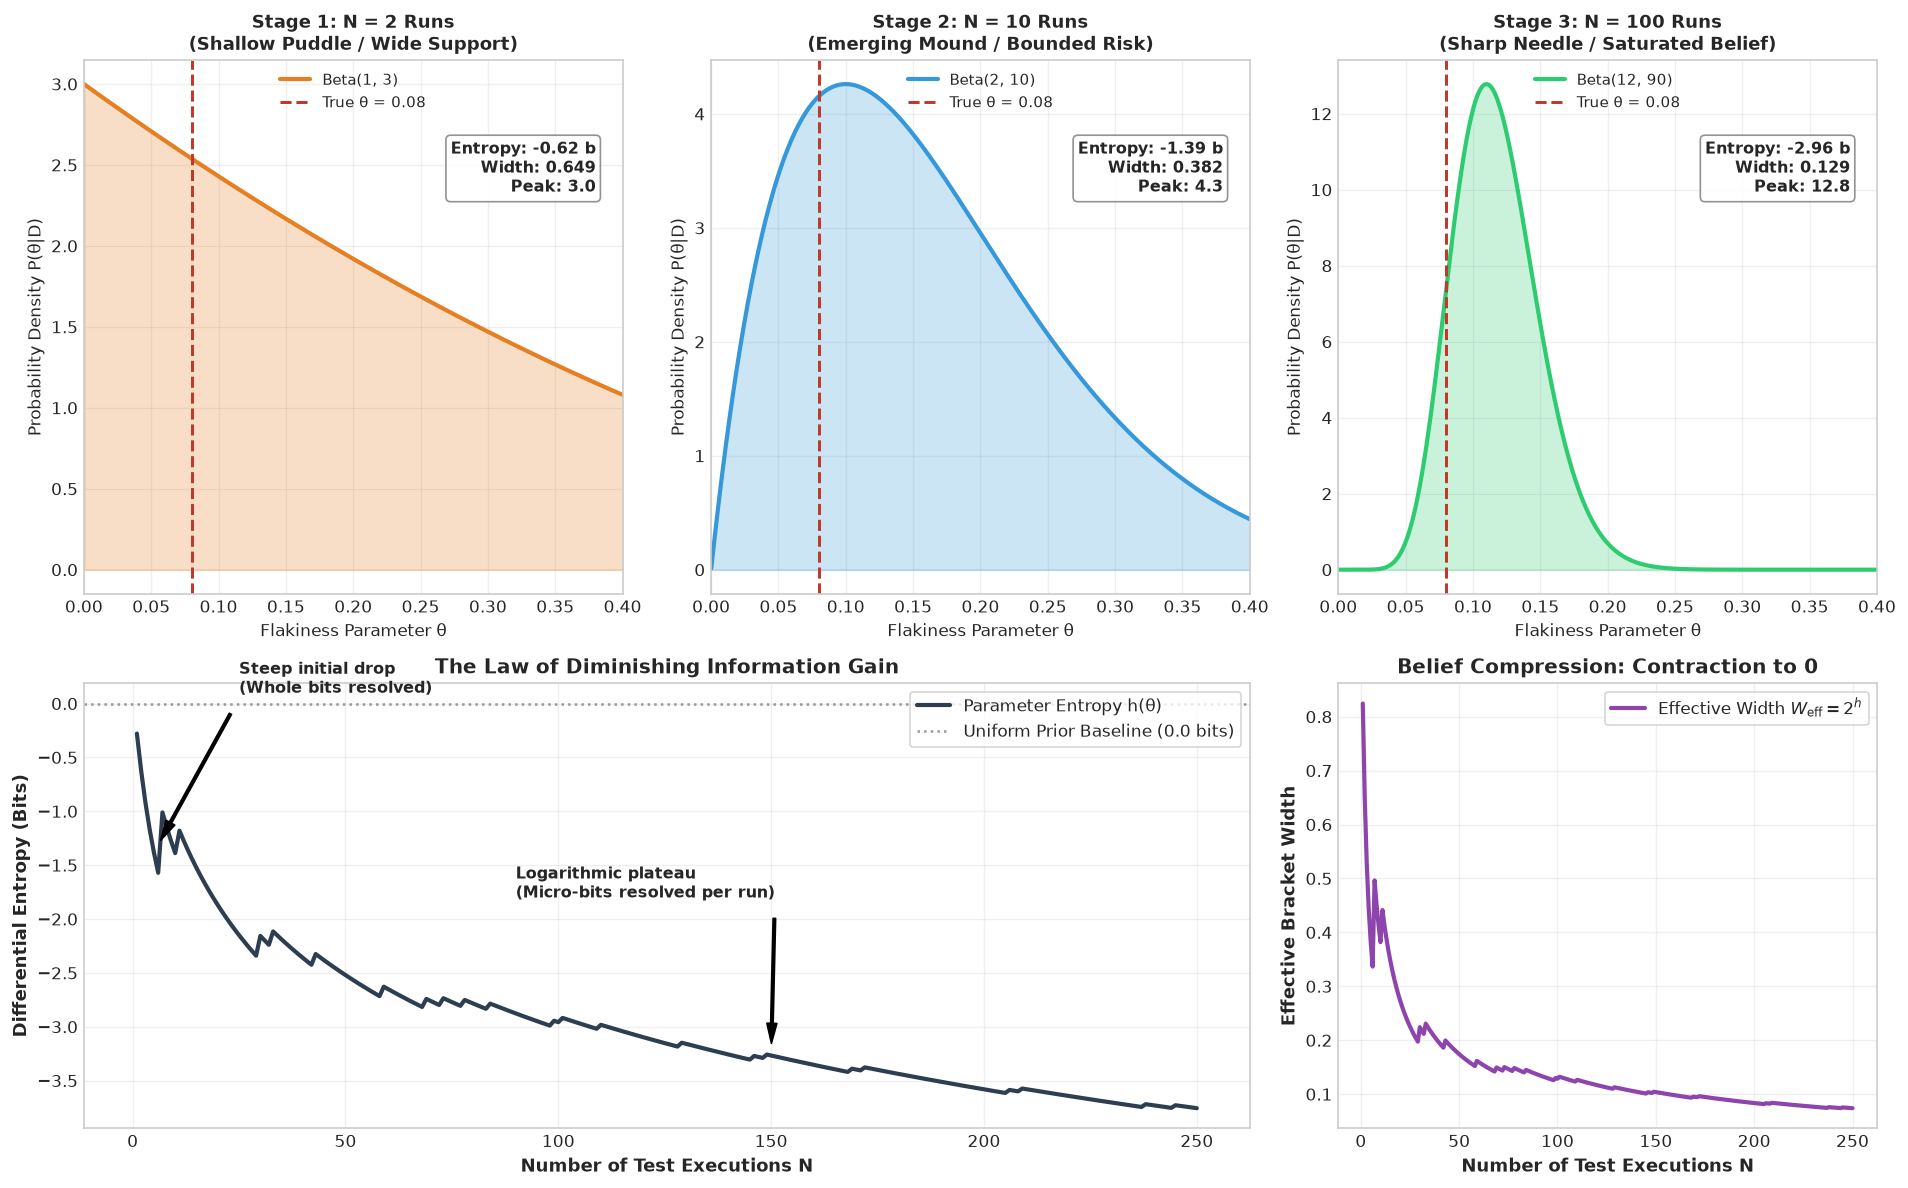

In [4]:
np.random.seed(42)  # Fixed seed for reproducible CI runs
theta_true = 0.08
num_runs = 250
# Generate synthetic test execution history (1 = Fail, 0 = Pass)
test_runs = (np.random.uniform(0, 1, size=num_runs) < theta_true).astype(int)

# Create 4-panel diagnostic figure
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 1.0])

theta_grid = np.linspace(0.0001, 0.45, 500)
alpha_0, beta_0 = 1.0, 1.0

# -----------------------------------------------------------
# Top Row: The 3 Stages of Belief (Separate subplots for clarity)
# -----------------------------------------------------------
milestones = [
    (2, "Stage 1: N = 2 Runs\n(Shallow Puddle / Wide Support)", '#e67e22'),
    (10, "Stage 2: N = 10 Runs\n(Emerging Mound / Bounded Risk)", '#3498db'),
    (100, "Stage 3: N = 100 Runs\n(Sharp Needle / Saturated Belief)", '#2ecc71')
]

for idx, (N_cp, title, col) in enumerate(milestones):
    ax = fig.add_subplot(gs[0, idx])
    k_cp = np.sum(test_runs[:N_cp])
    a_cp = alpha_0 + k_cp
    b_cp = beta_0 + (N_cp - k_cp)
    h_cp = beta_entropy_bits(a_cp, b_cp)
    w_cp = effective_width(h_cp)
    
    pdf = beta_dist.pdf(theta_grid, a_cp, b_cp)
    ax.plot(theta_grid, pdf, color=col, lw=2.5, label=f"Beta({int(a_cp)}, {int(b_cp)})")
    ax.fill_between(theta_grid, pdf, color=col, alpha=0.25)
    ax.axvline(theta_true, color='#c0392b', ls='--', lw=1.8, label=f"True θ = {theta_true}")
    
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("Flakiness Parameter θ", fontsize=10)
    ax.set_ylabel("Probability Density P(θ|D)", fontsize=10)
    ax.set_xlim(0, 0.40)
    
    # Annotate metrics
    ax.text(0.95, 0.85, f"Entropy: {h_cp:+.2f} b\nWidth: {w_cp:.3f}\nPeak: {np.max(pdf):.1f}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9.5, fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.85, ec="gray"))
    ax.legend(loc='upper center', fontsize=9)
    ax.grid(True, alpha=0.3)

# -----------------------------------------------------------
# Bottom Row: Left = Entropy Decay, Right = Effective Width
# -----------------------------------------------------------
n_range = np.arange(1, 251)
cum_failures = np.cumsum(test_runs)
cum_passes = n_range - cum_failures

entropy_curve = [beta_entropy_bits(alpha_0 + k, beta_0 + p) for k, p in zip(cum_failures, cum_passes)]
width_curve = [effective_width(h) for h in entropy_curve]

# Panel 4: Entropy Decay vs N
ax_ent = fig.add_subplot(gs[1, :2])
ax_ent.plot(n_range, entropy_curve, color='#2c3e50', lw=2.5, label='Parameter Entropy h(θ)')
ax_ent.axhline(0, color='gray', ls=':', alpha=0.8, label='Uniform Prior Baseline (0.0 bits)')
ax_ent.set_xlabel("Number of Test Executions N", fontsize=11, fontweight='bold')
ax_ent.set_ylabel("Differential Entropy (Bits)", fontsize=11, fontweight='bold')
ax_ent.set_title("The Law of Diminishing Information Gain", fontsize=12, fontweight='bold')

# Annotations
ax_ent.annotate("Steep initial drop\n(Whole bits resolved)", xy=(5, entropy_curve[4]), xytext=(25, 0.1),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
                fontsize=9.5, fontweight='bold')
ax_ent.annotate("Logarithmic plateau\n(Micro-bits resolved per run)", xy=(150, entropy_curve[149]), xytext=(90, -1.8),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=6),
                fontsize=9.5, fontweight='bold')
ax_ent.legend(loc='upper right', frameon=True)
ax_ent.grid(True, alpha=0.3)

# Panel 5: Effective Support Width Contraction
ax_w = fig.add_subplot(gs[1, 2])
ax_w.plot(n_range, width_curve, color='#8e44ad', lw=2.5, label=r'Effective Width $W_{\mathrm{eff}} = 2^h$')
ax_w.set_xlabel("Number of Test Executions N", fontsize=11, fontweight='bold')
ax_w.set_ylabel("Effective Bracket Width", fontsize=11, fontweight='bold')
ax_w.set_title("Belief Compression: Contraction to 0", fontsize=12, fontweight='bold')
ax_w.grid(True, alpha=0.3)
ax_w.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


---

## 5. From Wasted Bits to Operational Action

Entropy tells us *how uncertain* we are, but production engineering requires **actionable decisions**:
* **95% Credible Interval (HDI / Equal-Tailed):** What is the plausible range of the true failure rate $\theta$?
* **SLA Risk Probability:** What is $P(\theta > \theta_{\text{SLA}} \mid D)$—the probability our test suite violates its reliability budget?
* **Posterior Predictive Probability:** If we run a 5-check merge gate right now, what is the probability all 5 pass?
  $$P(\text{5 passes} \mid D) = \int_0^1 (1 - \theta)^5\, p(\theta \mid D)\, d\theta$$

Notice how **integrating over posterior uncertainty** prevents overconfident SLA promises compared to plugging in a single point estimate!

=== Beta(9, 93) Credible Intervals vs. Entropy Width ===
95% Equal-Tailed Interval (ETI): [0.0416, 0.1501] (width: 0.1086)
95% Highest Density Interval (HDI): [0.0374, 0.1438] (width: 0.1065)
Effective Width W_eff = 2^h:      0.1122 (h = -3.16 bits)

=== Beta(2, 10) SLA Tail Risk ===
P(theta > 0.05 | Beta(2, 10)): 0.8981 (89.8%)

=== Beta(2, 10) Future 10-Run Pass Streak ===
Exact Beta-Binomial Predictive: 0.2619 (26.19%) [exact: 11/42 = 0.2619]
Naive Plug-in (1 - E[theta])^10: 0.1615 (16.15%)
Difference (Underestimation):   10.04 percentage points



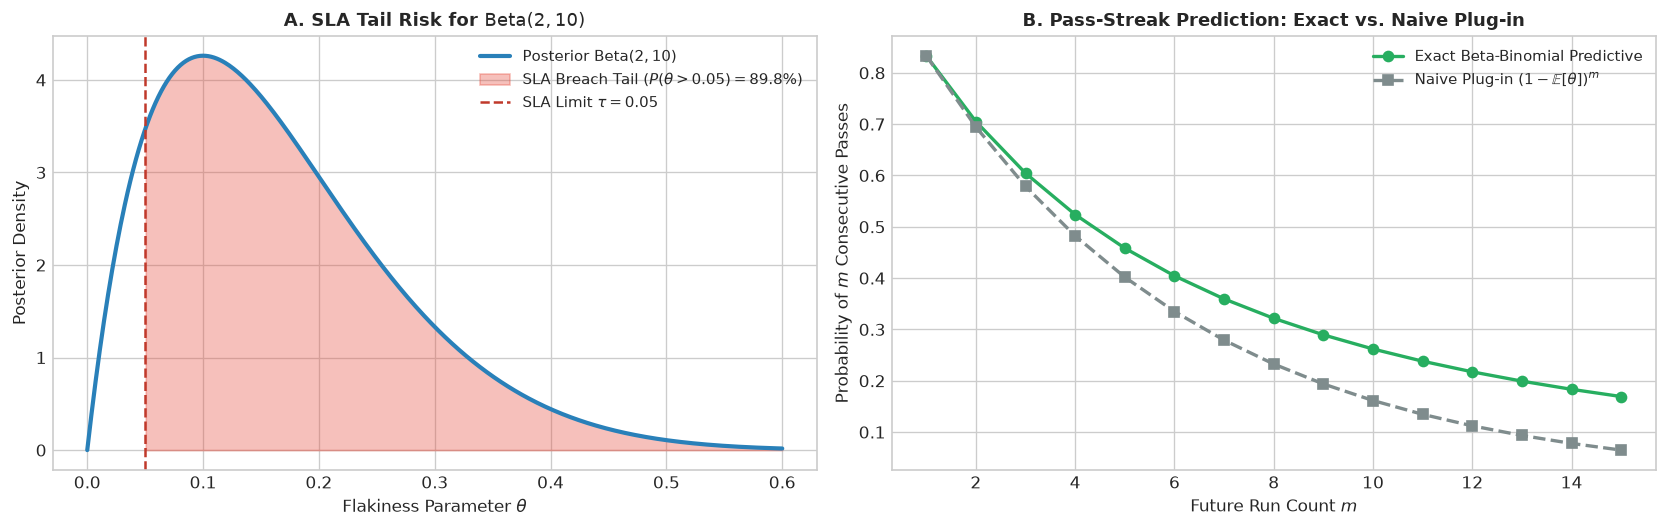

In [5]:
from scipy.optimize import minimize_scalar

def beta_equal_tailed_interval(alpha, beta, prob=0.95):
    """Computes (1 - prob)/2 and 1 - (1 - prob)/2 quantiles for Beta(alpha, beta)."""
    tail = (1.0 - prob) / 2.0
    # ppf: percent point function (quantile / inverse CDF).
    # [tail, 1.0 - tail] gives the lower and upper quantiles for prob mass.
    low, high = beta_dist.ppf([tail, 1.0 - tail], alpha, beta)
    return low, high

def beta_hdi(alpha, beta, prob=0.95):
    """Computes shortest (1 - prob) Highest Density Interval for Beta(alpha, beta)."""
    if alpha <= 1.0:
        return 0.0, float(beta_dist.ppf(prob, alpha, beta))
    if beta <= 1.0:
        return float(beta_dist.ppf(1.0 - prob, alpha, beta)), 1.0
    
    def interval_width(low):
        # cdf: cumulative distribution function P(theta <= low)
        cdf_low = beta_dist.cdf(low, alpha, beta)
        # ppf: finds matching upper quantile enclosing target 'prob' mass
        high = beta_dist.ppf(cdf_low + prob, alpha, beta)
        return high - low
    
    # 1D bounded minimization: find lower bound minimizing interval width.
    # bounds=(0.0, 1.0 - prob) ensures upper quantile <= 1.0.
    res = minimize_scalar(interval_width, bounds=(0.0, 1.0 - prob), method='bounded')
    # res.x: optimal lower bound for the shortest HDI interval
    low = res.x
    high = beta_dist.ppf(beta_dist.cdf(low, alpha, beta) + prob, alpha, beta)
    return float(low), float(high)

def beta_sla_tail_risk(alpha, beta, tau=0.05):
    """Computes SLA breach probability P(theta > tau | alpha, beta)."""
    # 1.0 - cdf computes upper-tail probability mass P(theta > tau)
    return float(1.0 - beta_dist.cdf(tau, alpha, beta))

def beta_binomial_pass_streak(alpha, beta, m=10):
    """
    Computes exact probability that the next m runs all pass:
    P(m passes) = prod_{j=0}^{m-1} (beta + j) / (alpha + beta + j)
    Also returns the naive point-estimate plug-in (1 - E[theta])^m.
    """
    terms = [(beta + j) / (alpha + beta + j) for j in range(m)]
    exact_prob = float(np.prod(terms))
    mean_theta = alpha / (alpha + beta)
    naive_prob = float((1.0 - mean_theta) ** m)
    return exact_prob, naive_prob

# Verification 1: Beta(9, 93) Credible Intervals vs Effective Width
eti_low, eti_high = beta_equal_tailed_interval(9, 93, 0.95)
hdi_low, hdi_high = beta_hdi(9, 93, 0.95)
h_9_93 = beta_entropy_bits(9, 93)
w_eff_9_93 = effective_width(h_9_93)

print("=== Beta(9, 93) Credible Intervals vs. Entropy Width ===")
print(f"95% Equal-Tailed Interval (ETI): [{eti_low:.4f}, {eti_high:.4f}] (width: {eti_high - eti_low:.4f})")
print(f"95% Highest Density Interval (HDI): [{hdi_low:.4f}, {hdi_high:.4f}] (width: {hdi_high - hdi_low:.4f})")
print(f"Effective Width W_eff = 2^h:      {w_eff_9_93:.4f} (h = {h_9_93:.2f} bits)\n")

# Verification 2: SLA Tail Risk for Beta(2, 10)
tau_sla = 0.05
p_breach = beta_sla_tail_risk(2, 10, tau=tau_sla)
print("=== Beta(2, 10) SLA Tail Risk ===")
print(f"P(theta > {tau_sla} | Beta(2, 10)): {p_breach:.4f} ({p_breach * 100:.1f}%)\n")

# Verification 3: Beta-Binomial Pass Streak for Beta(2, 10), m=10
exact_streak, naive_streak = beta_binomial_pass_streak(2, 10, m=10)
print("=== Beta(2, 10) Future 10-Run Pass Streak ===")
print(f"Exact Beta-Binomial Predictive: {exact_streak:.4f} ({exact_streak * 100:.2f}%) [exact: 11/42 = {11/42:.4f}]")
print(f"Naive Plug-in (1 - E[theta])^10: {naive_streak:.4f} ({naive_streak * 100:.2f}%)")
print(f"Difference (Underestimation):   {(exact_streak - naive_streak) * 100:.2f} percentage points\n")

# Visualization: Diagnostic 2-Panel Figure
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: SLA Tail Risk & Intervals for Beta(2, 10)
theta_vals = np.linspace(0.0, 0.6, 500)
pdf_2_10 = beta_dist.pdf(theta_vals, 2, 10)
axes[0].plot(theta_vals, pdf_2_10, label=r'Posterior $\mathrm{Beta}(2, 10)$', color='#2980b9', lw=2.5)
mask_breach = theta_vals >= tau_sla
axes[0].fill_between(
    theta_vals[mask_breach],
    pdf_2_10[mask_breach],
    color='#e74c3c',
    alpha=0.35,
    label=f'SLA Breach Tail ($P(\\theta > 0.05) = {p_breach*100:.1f}\\%$)'
)
axes[0].axvline(tau_sla, color='#c0392b', linestyle='--', label=r'SLA Limit $\tau = 0.05$')
axes[0].set_title(r"A. SLA Tail Risk for $\mathrm{Beta}(2, 10)$", fontsize=11, fontweight='bold')
axes[0].set_xlabel(r"Flakiness Parameter $\theta$", fontsize=10)
axes[0].set_ylabel("Posterior Density", fontsize=10)
axes[0].legend(fontsize=9, loc='upper right')

# Panel 2: Predictive Pass Streak vs Streak Length m
m_range = np.arange(1, 16)
exact_probs = [beta_binomial_pass_streak(2, 10, m=m)[0] for m in m_range]
naive_probs = [beta_binomial_pass_streak(2, 10, m=m)[1] for m in m_range]

axes[1].plot(m_range, exact_probs, 'o-', color='#27ae60', lw=2, label='Exact Beta-Binomial Predictive')
axes[1].plot(m_range, naive_probs, 's--', color='#7f8c8d', lw=2, label=r'Naive Plug-in $(1 - \mathbb{E}[\theta])^m$')
axes[1].set_title("B. Pass-Streak Prediction: Exact vs. Naive Plug-in", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Future Run Count $m$", fontsize=10)
axes[1].set_ylabel("Probability of $m$ Consecutive Passes", fontsize=10)
axes[1].legend(fontsize=9, loc='upper right')

plt.tight_layout()
plt.show()


---

## 6. 3-Tier Exercises & Explorations

### Tier 1: Warmup — Entropy Calculation & Effective Width
1. Compute the binary entropy $H_2(\theta)$ for a test with $\theta = 0.05$ (fails $5\%$ of the time).
2. For a test posterior $\text{Beta}(4, 36)$, calculate the differential entropy $h(\theta)$ in bits and its corresponding effective width $W_{\text{eff}} = 2^h$.
3. What is the expected failure rate for a test with prior $\text{Beta}(2, 98)$ after observing $1$ failure in $10$ runs?

### Tier 2: Intermediate — Prior Sensitivity Analysis
Compare two engineering teams analyzing the exact same test outcome: **$1$ failure in $20$ runs**.
* **Team A (Skeptical)**: Uses prior $\text{Beta}(1, 99)$ (assumes tests are generally solid).
* **Team B (Agnostic)**: Uses prior $\text{Beta}(1, 1)$ (assumes nothing).
Calculate the posterior mean, 95% credible interval, and posterior entropy for both teams.

### Tier 3: Advanced Research — The Information Stopping Rule
Write an automated function `run_test_until_certain(theta_true, target_entropy_reduction=2.0)` that executes simulated CI runs one-by-one.
* It stops running tests as soon as the total parameter entropy has dropped by $2.0\text{ bits}$ from the prior.
* Plot the distribution of required test runs $N_{\text{stop}}$ across 1,000 Monte Carlo trials.


In [6]:
# Solution verification for Tier 1:
h_05 = binary_entropy(0.05)
h_post_t1 = beta_entropy_bits(4, 36)
w_post_t1 = effective_width(h_post_t1)
mean_t1 = (2 + 1) / (2 + 98 + 10)

print("--- Tier 1 Solutions ---")
print(f"1. Binary entropy H2(0.05):              {h_05:.4f} bits")
print(f"2. Beta(4, 36) Differential Entropy:     {h_post_t1:.4f} bits")
print(f"   Beta(4, 36) Effective Width:          {w_post_t1:.4f} ({w_post_t1*100:.2f}% of interval)")
print(f"3. Posterior Mean for Beta(2, 98) + (1, 9): {mean_t1:.4f} ({mean_t1*100:.2f}%)")


--- Tier 1 Solutions ---
1. Binary entropy H2(0.05):              0.2864 bits
2. Beta(4, 36) Differential Entropy:     -2.4620 bits
   Beta(4, 36) Effective Width:          0.1815 (18.15% of interval)
3. Posterior Mean for Beta(2, 98) + (1, 9): 0.0273 (2.73%)


In [7]:
# Solution verification for Tier 2:
# Outcome: k=1, N=20
k_obs, N_obs = 1, 20

# Team A: Beta(1, 99) -> Beta(1 + 1, 99 + 19) = Beta(2, 118)
a_A, b_A = 1 + k_obs, 99 + (N_obs - k_obs)
mean_A = a_A / (a_A + b_A)
ci_A = beta_dist.interval(0.95, a_A, b_A)
h_A = beta_entropy_bits(a_A, b_A)

# Team B: Beta(1, 1) -> Beta(1 + 1, 1 + 19) = Beta(2, 20)
a_B, b_B = 1 + k_obs, 1 + (N_obs - k_obs)
mean_B = a_B / (a_B + b_B)
ci_B = beta_dist.interval(0.95, a_B, b_B)
h_B = beta_entropy_bits(a_B, b_B)

print("\n--- Tier 2 Solutions ---")
print(f"Team A (Skeptical Prior Beta(1, 99)):")
print(f"  Posterior Mean: {mean_A:.4f} ({mean_A*100:.2f}%)")
print(f"  95% CI:         [{ci_A[0]:.4f}, {ci_A[1]:.4f}]")
print(f"  Entropy:        {h_A:.4f} bits")

print(f"\nTeam B (Agnostic Prior Beta(1, 1)):")
print(f"  Posterior Mean: {mean_B:.4f} ({mean_B*100:.2f}%)")
print(f"  95% CI:         [{ci_B[0]:.4f}, {ci_B[1]:.4f}]")
print(f"  Entropy:        {h_B:.4f} bits")



--- Tier 2 Solutions ---
Team A (Skeptical Prior Beta(1, 99)):
  Posterior Mean: 0.0167 (1.67%)
  95% CI:         [0.0020, 0.0459]
  Entropy:        -4.6376 bits

Team B (Agnostic Prior Beta(1, 1)):
  Posterior Mean: 0.0909 (9.09%)
  95% CI:         [0.0117, 0.2382]
  Entropy:        -2.2219 bits


In [8]:
# Solution verification for Tier 3:
print("\n--- Tier 3 Simulation: Information Stopping Rule ---")

def run_test_until_certain(theta_true=0.08, target_drop=2.0, max_runs=100):
    a, b = 1.0, 1.0
    h_init = beta_entropy_bits(a, b) # 0.0 bits
    for n in range(1, max_runs + 1):
        y = 1 if np.random.rand() < theta_true else 0
        a += y
        b += (1 - y)
        h_current = beta_entropy_bits(a, b)
        if (h_init - h_current) >= target_drop:
            return n
    return max_runs

trials = 1000
stopping_runs = [run_test_until_certain(theta_true=0.08, target_drop=2.0) for _ in range(trials)]
avg_runs = np.mean(stopping_runs)
median_runs = np.median(stopping_runs)

print(f"Monte Carlo Trials: {trials:,}")
print(f"Target Entropy Drop: 2.0 bits (compressing belief by 4x)")
print(f"Average Runs to Stop: {avg_runs:.1f} runs")
print(f"Median Runs to Stop:  {median_runs:.1f} runs")
print(f"90th Percentile:      {np.percentile(stopping_runs, 90):.1f} runs")



--- Tier 3 Simulation: Information Stopping Rule ---
Monte Carlo Trials: 1,000
Target Entropy Drop: 2.0 bits (compressing belief by 4x)
Average Runs to Stop: 17.6 runs
Median Runs to Stop:  17.0 runs
90th Percentile:      31.0 runs
